<a href="https://colab.research.google.com/github/sarahliu-mma/Quantitative-Trading-Pipeline_FIAM-Hackathon-2026/blob/main/notebooks/01_data_inspection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Inspection and Exploration

## 1. Setup and data loading
Import libraries and load the JKP characteristic list and the monthly stock panel.

In [1]:
import numpy as np
import pandas as pd

In [4]:
# Load the list of JKP characteristics (147 features)
fact_list = pd.read_csv('/content/drive/MyDrive/FIAM Hackathon/factor_char_list.csv')

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Load the panel data, which contains 51 identifier/auxiliary columns and 147 JKP features
dt = pd.read_parquet('/content/drive/MyDrive/FIAM Hackathon/chars_final_with_names.parquet')
dt.head()

,id,permno,permco,gvkey,iid,excntry,exch_main,common,primary_sec,bidask,...,qmj_prof,qmj_growth,qmj_safety,qmj,me_lag1,ticker,company_name,ticker_name_reference_date,ticker_name_source,ticker_name_status
0,10001,10001,7953,012994,01,USA,1,1,1,0,...,-0.793438,-1.174184,-0.554461,-1.339223,115.57776,EGAS,GAS NATURAL INC,2015-01-30,CRSP_monthly_security_history,verified_in_observation_month
1,10025,10025,7975,011903,01,USA,1,1,1,0,...,-0.659718,-1.648672,-1.076800,-1.539792,295.46015,AEPI,A E P INDUSTRIES INC,2015-01-30,CRSP_monthly_security_history,verified_in_observation_month
2,10026,10026,7976,012825,01,USA,1,1,1,0,...,1.291849,-1.083642,1.560033,1.060720,2031.60606,JJSF,J & J SNACK FOODS CORP,2015-01-30,CRSP_monthly_security_history,verified_in_observation_month
3,10028,10028,7978,012096,01,USA,1,1,1,0,...,0.288480,1.542084,-0.634534,0.691674,14.91328,DGSE,D G S E COMPANIES INC,2015-01-30,CRSP_monthly_security_history,verified_in_observation_month
4,10032,10032,7980,012945,01,USA,1,1,1,0,...,-0.891624,-0.555288,0.647570,-0.687090,1384.86205,PLXS,PLEXUS CORP,2015-01-30,CRSP_monthly_security_history,verified_in_observation_month


## 2. Panel structure
Size of the panel, number of unique stocks, sample period, duplicate stock-months, and the number of stocks per month.

In [6]:
# Inspect the data structure
rows, columns = dt.shape[0], dt.shape[1]
print(f'The data has {rows} rows and {columns} columns.')

# Count the number of unique stocks in the dataset
npermno = len(dt.groupby('permno'))
print(f'It consists of {npermno} unique stocks,')

# Find the time period covered by the data
dt['eom'] = pd.to_datetime(dt['eom'])
print(f'starting from {dt['eom'].min()} to {dt['eom'].max()}')

# Count the missing values in each column
print(f'Not available data {dt.isna().sum().sort_values(ascending = False)}')

The data has 529082 rows and 198 columns.
It consists of 6561 unique stocks,
starting from 2015-01-31 00:00:00 to 2026-08-31 00:00:00
Not available data comp_tpci             500623
comp_exchg            500623
rd5_at                300295
rd_sale               265758
rd_me                 240475
                       ...  
ret                        0
ret_lag_dif                0
ret_exc                    0
age                        0
ticker_name_status         0
Length: 198, dtype: int64


In [7]:
# Check whether any stock appears more than once in the same month
dt.duplicated(subset = ['permno','eom']).sum()

np.int64(0)

In [8]:
# Count the number of stocks in each month
nstock_num = dt['eom'].value_counts().sort_index()

In [9]:
print(nstock_num)

eom
2015-01-31    3729
2015-02-28    3728
2015-03-31    3719
2015-04-30    3715
2015-05-31    3721
              ... 
2026-04-30    3567
2026-05-31    3550
2026-06-30    3531
2026-07-31    3518
2026-08-31    3497
Name: count, Length: 140, dtype: int64


<Axes: xlabel='eom'>

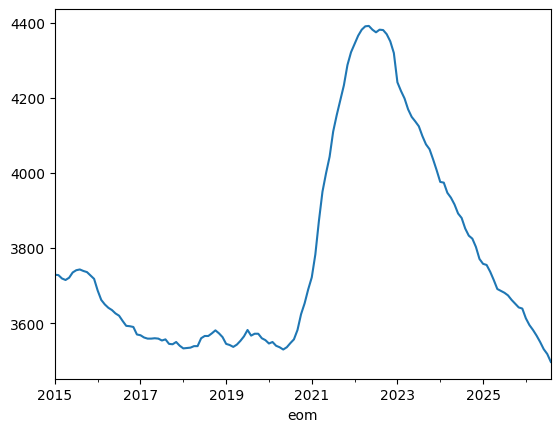

In [10]:
nstock_num.plot()

## 3. Features vs. identifiers
Confirm that all 147 JKP features are in the data and separate them from the 51 identifier/auxiliary columns.

In [11]:
# Check whether the data contains all of the JKP features
dt_feature = dt.columns.tolist()

missing_features = list()
for factor in fact_list['variable']:
  if factor not in dt_feature:
    missing_features.append(factor)

print("Features not in dataset:", missing_features)
print('Number of missing features:',len(set(missing_features)))

Features not in dataset: []
Number of missing features: 0


In [12]:
identifiers = []
fact_set = set(fact_list['variable'].tolist())
for f in dt_feature:
  if f not in fact_set:
    identifiers.append(f)
print(identifiers)

['id', 'permno', 'permco', 'gvkey', 'iid', 'excntry', 'exch_main', 'common', 'primary_sec', 'bidask', 'primaryexch', 'conditionaltype', 'crsp_nyse', 'shrcd', 'exchcd', 'crsp_shrcd', 'crsp_exchcd', 'comp_tpci', 'comp_exchg', 'curcd', 'fx', 'date', 'eom', 'adjfct', 'shares', 'me', 'me_company', 'prc_local', 'prc_high', 'prc_low', 'dolvol', 'tvol', 'ret', 'ret_local', 'ret_exc', 'ret_lag_dif', 'source_crsp', 'ret_exc_lead1m', 'obs_main', 'gics', 'sic', 'naics', 'ff49', 'size_grp', 'ret_exc_wins', 'me_lag1', 'ticker', 'company_name', 'ticker_name_reference_date', 'ticker_name_source', 'ticker_name_status']


## 4. Target variable (`ret_exc_lead1m`)
Missing targets, summary statistics, distribution and tails, and the monthly cross-sectional mean and standard deviation.

In [13]:
# Count the missing values of the target variable
dt['ret_exc_lead1m'].isna().sum()


np.int64(5957)

In [14]:
# Summary statistics of the target variable
dt['ret_exc_lead1m'].describe()

,ret_exc_lead1m
count,523125.000000
mean,0.005272
std,0.248610
min,-1.004157
25%,-0.077051
50%,-0.001156
75%,0.068433
max,53.997100


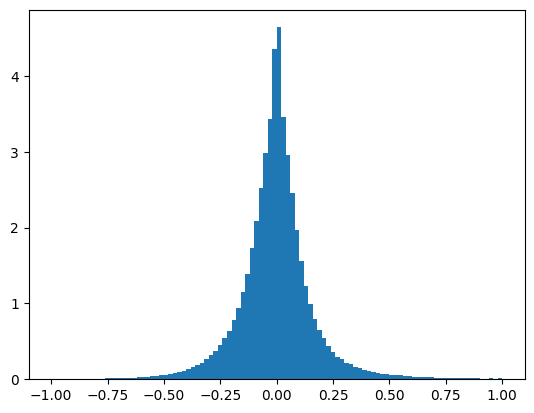

In [15]:
import matplotlib.pyplot as plt

# Distribution of the target variable
fig,axe = plt.subplots(1,1)
axe.hist(dt['ret_exc_lead1m'],bins= 100, range = (-1,1), density= True)
axe.set_xticks(np.arange(-1,1.1,0.25))
plt.show()

<Axes: ylabel='Frequency'>

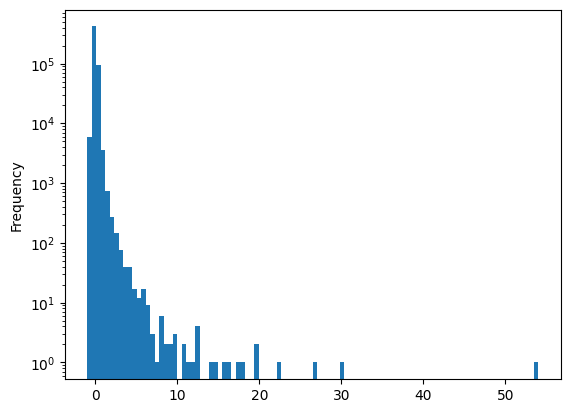

In [16]:
# Distribution of the target variable with a log-scaled frequency axis
# Check for outliers (extreme values in the tails)
dt['ret_exc_lead1m'].plot.hist(bins=100, log=True)

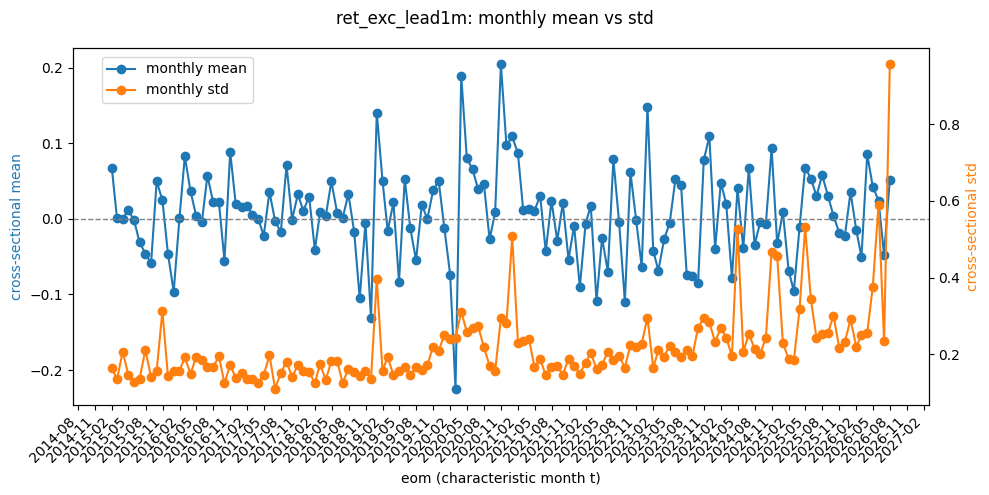

In [17]:
# Time series of the monthly cross-sectional mean and standard deviation of the target variable
import matplotlib.dates as mdates

monthly_mean_ret_exc_lead1m = dt.groupby('eom')['ret_exc_lead1m'].mean()
monthly_std_ret_exc_lead1m = dt.groupby('eom')['ret_exc_lead1m'].std()



fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(monthly_mean_ret_exc_lead1m.index, monthly_mean_ret_exc_lead1m.values,
         'o-', linewidth=1.5, color='tab:blue', label='monthly mean')
ax1.set_xlabel('eom (characteristic month t)')
ax1.set_ylabel('cross-sectional mean', color='tab:blue')
ax1.axhline(0, color='gray', linestyle='--', linewidth=1)

ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.setp(ax1.get_xticklabels(), rotation=45, ha='right')

ax2 = ax1.twinx()
ax2.plot(monthly_std_ret_exc_lead1m.index, monthly_std_ret_exc_lead1m.values,
         'o-', linewidth=1.5, color='tab:orange', label='monthly std')
ax2.set_ylabel('cross-sectional std', color='tab:orange')

fig.suptitle('ret_exc_lead1m: monthly mean vs std')
fig.legend(loc='upper left', bbox_to_anchor=(0.1, 0.9))
plt.tight_layout()
plt.show()


## 5. Missing values
Columns with the most missing values and how the missing ratio of each feature changes over time.

Top ten features with the most missing values:comp_tpci          500623
comp_exchg         500623
rd5_at             300295
rd_sale            265758
rd_me              240475
pi_nix             223497
dsale_dinv         199353
intrinsic_value    196284
inv_gr1            192102
seas_2_5na         157049
dtype: int64


<Axes: >

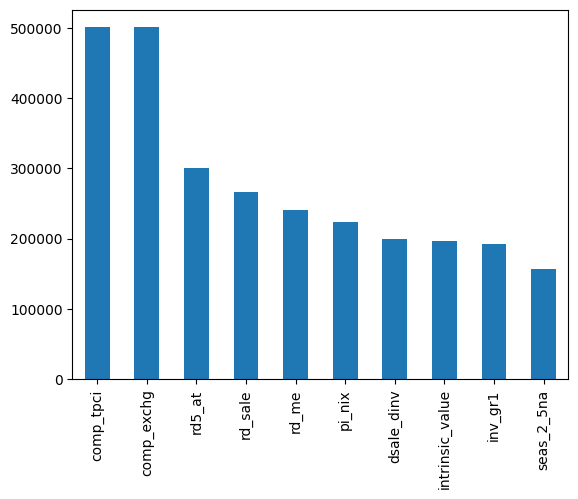

In [18]:
# Top ten columns with the most missing values
dt_na = dt.isna().sum().sort_values(ascending = False)
top_ten_missing_features = dt_na.head(10)
print(f'Top ten features with the most missing values:{top_ten_missing_features}')
top_ten_missing_features.plot.bar()

In [19]:
# Monthly missing ratio of each feature

na_ratio_bymonth = dt[fact_list['variable'].tolist()].isna().groupby(dt['eom']).mean()
na_ratio_bymonth

,age,aliq_at,aliq_mat,ami_126d,at_be,at_gr1,at_me,at_turnover,be_gr1a,be_me,...,taccruals_at,taccruals_ni,tangibility,tax_gr1a,turnover_126d,turnover_var_126d,z_score,zero_trades_126d,zero_trades_21d,zero_trades_252d
eom,,,,,,,,,,,,,,,,,,,,,
2015-01-31,0.0,0.134084,0.233575,0.013677,0.041566,0.012336,0.003754,0.008045,0.089032,0.041566,...,0.012336,0.012604,0.149638,0.021990,0.013677,0.013677,0.159024,0.013677,0.001877,0.029767
2015-02-28,0.0,0.131438,0.233637,0.012071,0.041309,0.009388,0.003487,0.007779,0.085837,0.041309,...,0.009120,0.009388,0.150215,0.016899,0.012071,0.012071,0.155848,0.012071,0.001073,0.032189
2015-03-31,0.0,0.129336,0.230169,0.010218,0.042216,0.007529,0.001882,0.004571,0.087120,0.042216,...,0.007529,0.007529,0.150578,0.010756,0.010218,0.010218,0.140898,0.010218,0.001076,0.029040
2015-04-30,0.0,0.129206,0.229610,0.010767,0.043607,0.007806,0.001884,0.004576,0.088291,0.043607,...,0.008075,0.008075,0.150202,0.010767,0.010767,0.010767,0.144818,0.010767,0.000538,0.026380
2015-05-31,0.0,0.127654,0.216877,0.011287,0.038699,0.006987,0.001344,0.003494,0.077130,0.038699,...,0.006987,0.006987,0.148885,0.013169,0.011287,0.011287,0.140822,0.011287,0.000806,0.023918
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-04-30,0.0,0.098402,0.207738,0.000561,0.088870,0.010373,0.005327,0.006728,0.132044,0.088870,...,0.010373,0.011214,0.164844,0.014298,0.000000,0.000000,0.100925,0.000000,0.001962,0.006448
2026-05-31,0.0,0.096056,0.192113,0.001408,0.078028,0.008169,0.004789,0.006197,0.115493,0.078028,...,0.008451,0.009577,0.162254,0.015211,0.000000,0.000000,0.099718,0.000000,0.001127,0.002817
2026-06-30,0.0,0.096856,0.190031,0.001416,0.078448,0.008496,0.004815,0.006231,0.117247,0.078448,...,0.008779,0.009912,0.163693,0.015293,0.000000,0.000000,0.100255,0.000000,0.000566,0.000000


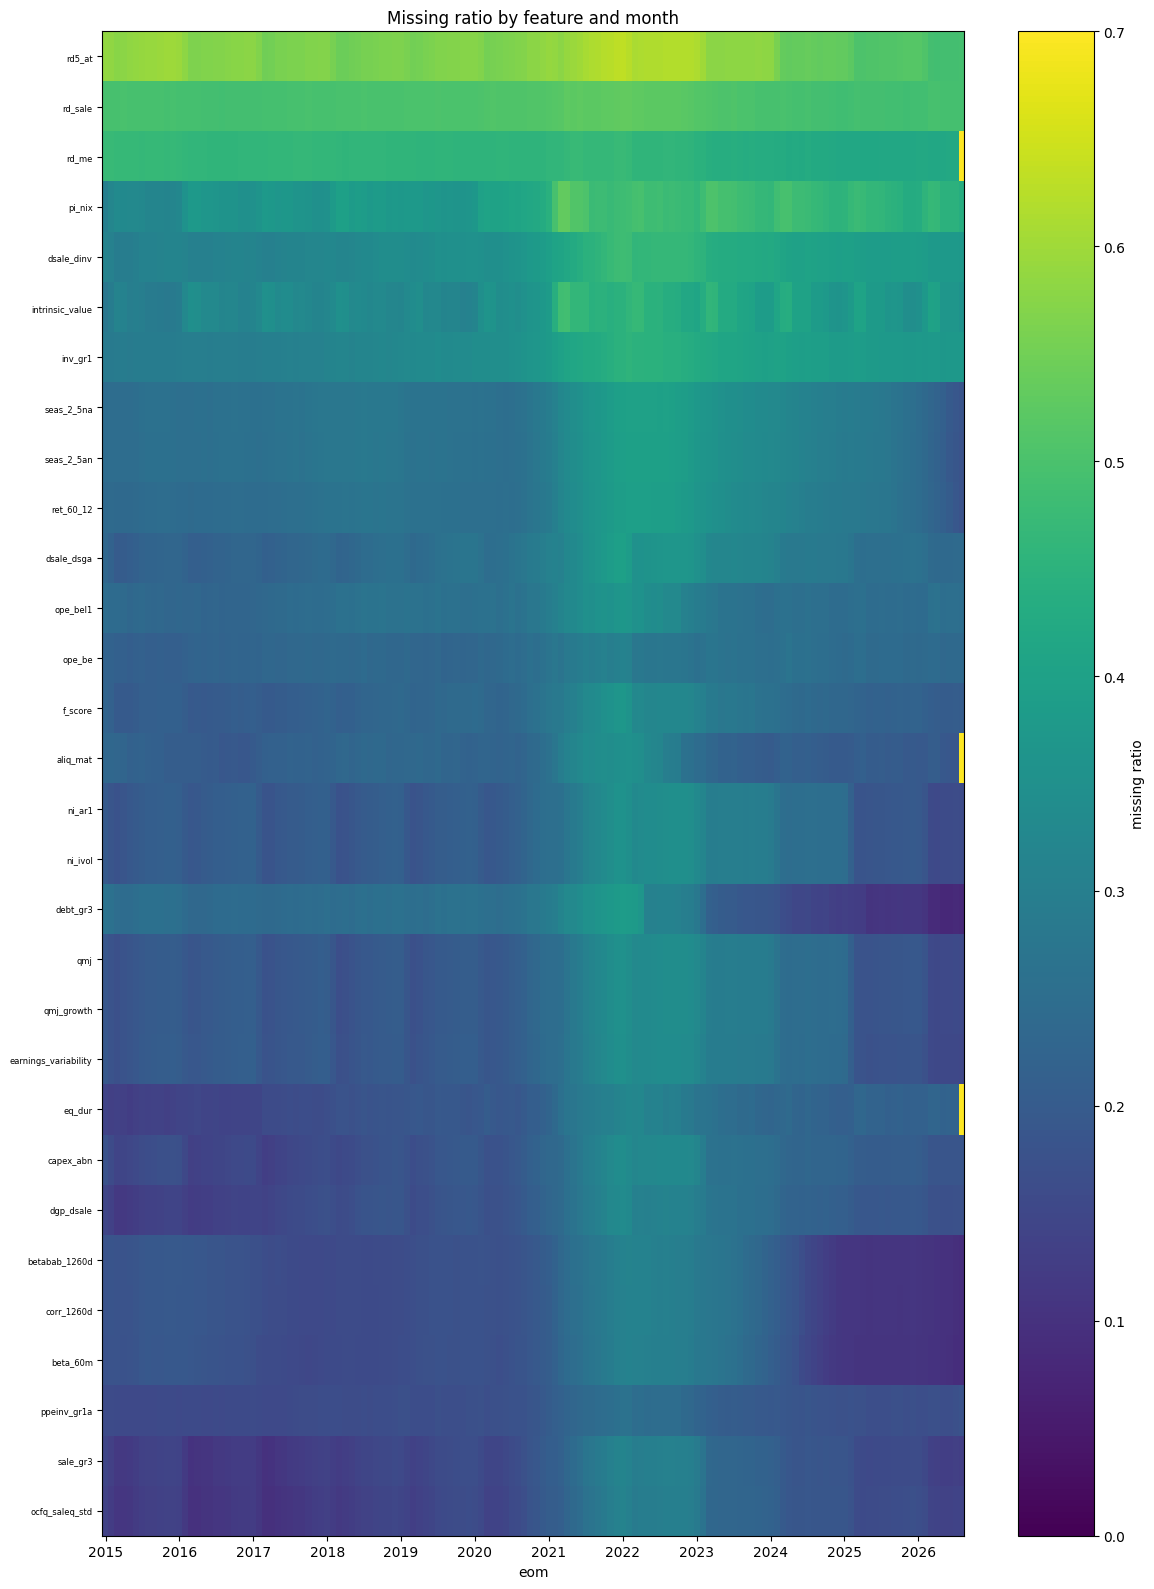

In [20]:
order = na_ratio_bymonth.mean().sort_values(ascending=False)
top = order.head(30).index
heat = na_ratio_bymonth[top].T

fig, ax = plt.subplots(figsize=(12, 16))
im = ax.imshow(heat.values, aspect='auto', cmap='viridis', vmin=0, vmax=0.7)

ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index, fontsize=6)

years = heat.columns.year
xticks = [i for i in range(len(years)) if i == 0 or years[i] != years[i - 1]]
ax.set_xticks(xticks)
ax.set_xticklabels(years[xticks])

ax.set_xlabel('eom')
ax.set_title('Missing ratio by feature and month')
fig.colorbar(im, ax=ax, label='missing ratio')
plt.tight_layout()
plt.show()

## 6. Feature distribution
Skewness and kurtosis of the 147 features.

In [23]:
# Feature distribution: skewness and kurtosis
feature_skew = dt[fact_list['variable'].tolist()].skew()
feature_kurt = dt[fact_list['variable'].tolist()].kurt()

print(feature_skew.sort_values().head(10))
print(feature_kurt.sort_values().head(10))


fcf_me       -476.711261
ni_me        -464.823385
eqnpo_me     -444.727974
ocf_me       -443.771313
fnl_gr1a     -405.916552
be_gr1a      -396.541458
ncoa_gr1a    -386.557102
nncoa_gr1a   -378.481693
gp_at        -335.124901
ebitda_mev   -331.740823
dtype: float64
qmj_safety         -1.200001
qmj_growth         -1.200000
qmj                -1.200000
qmj_prof           -1.200000
corr_1260d         -0.718475
ni_inc8q           -0.672564
mispricing_perf    -0.592717
f_score            -0.498804
prc_highprc_252d   -0.139186
mispricing_mgmt    -0.050975
dtype: float64
